# Native EmoWOZ context RoBERTa
Workstream 5 extension; original B4 implementation credited. Training uses the official train/dev partitions and native labels.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
import json

import pandas as pd
from IPython.display import Image, display

## Dev selection
Five seeds, three fixed epochs; test does not select checkpoints.

{'best_seed_on_dev': 0,
 'metric': 'weighted_f1_no_neutral',
 'test_used_for_selection': False,
 'window': 'all',
 'window_selection_source': 'reports/b4/selection.json',
 'max_len': 256,
 'system_history_retained': True}

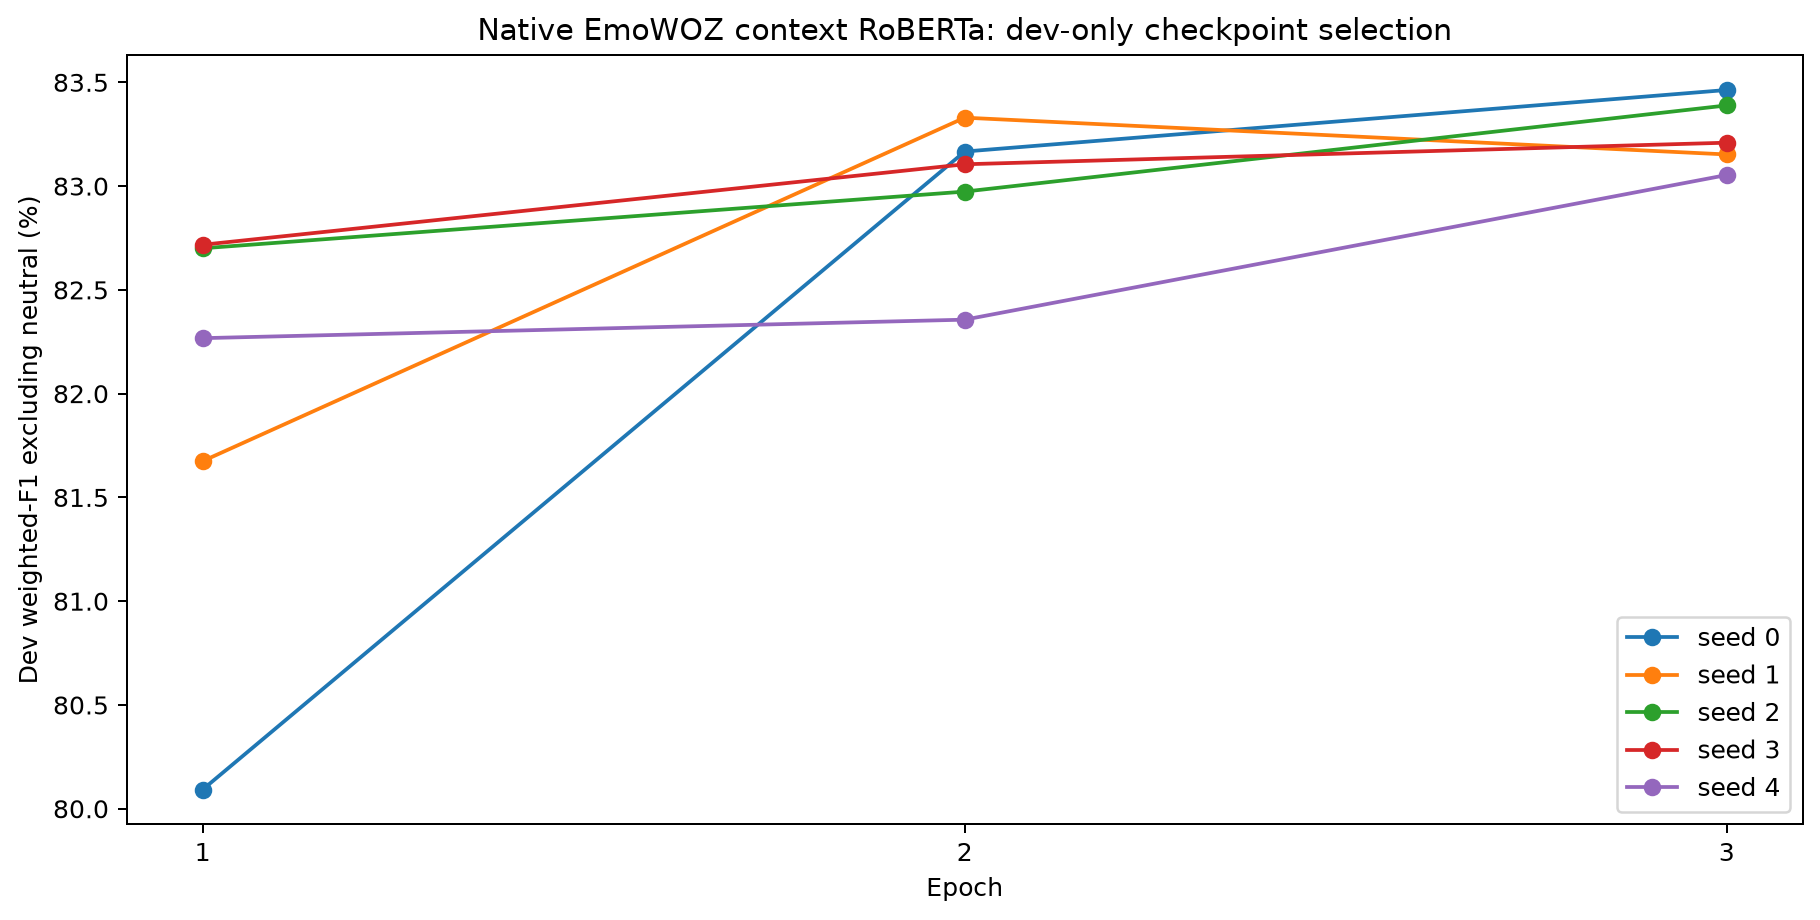

In [2]:
display(json.loads(Path("reports/b4/emowoz/selection.json").read_text()))
display(Image(filename="reports/b4/emowoz/figures/learning_curves.png"))

## Test comparison
Same native labels and targets for four utterance-only baselines and the context model.

,model,n,headline,std,ci_low,ci_high,macro_f1_no_neutral,macro_f1,derived_shift_f1
0,b1,8634,0.764975,0.000000,0.745574,0.782777,0.471027,0.533918,0.743627
1,b2_bigru,8634,0.770529,0.004528,0.748536,0.781185,0.482423,0.542609,0.739284
2,b2_bilstm,8634,0.770060,0.001909,0.748894,0.785174,0.487349,0.547008,0.741249
3,b3_roberta,8634,0.780853,0.002877,0.760494,0.800820,0.500039,0.560973,0.769253
4,b4_context,8634,0.846203,0.002458,0.831082,0.856499,0.557242,0.612996,0.805909


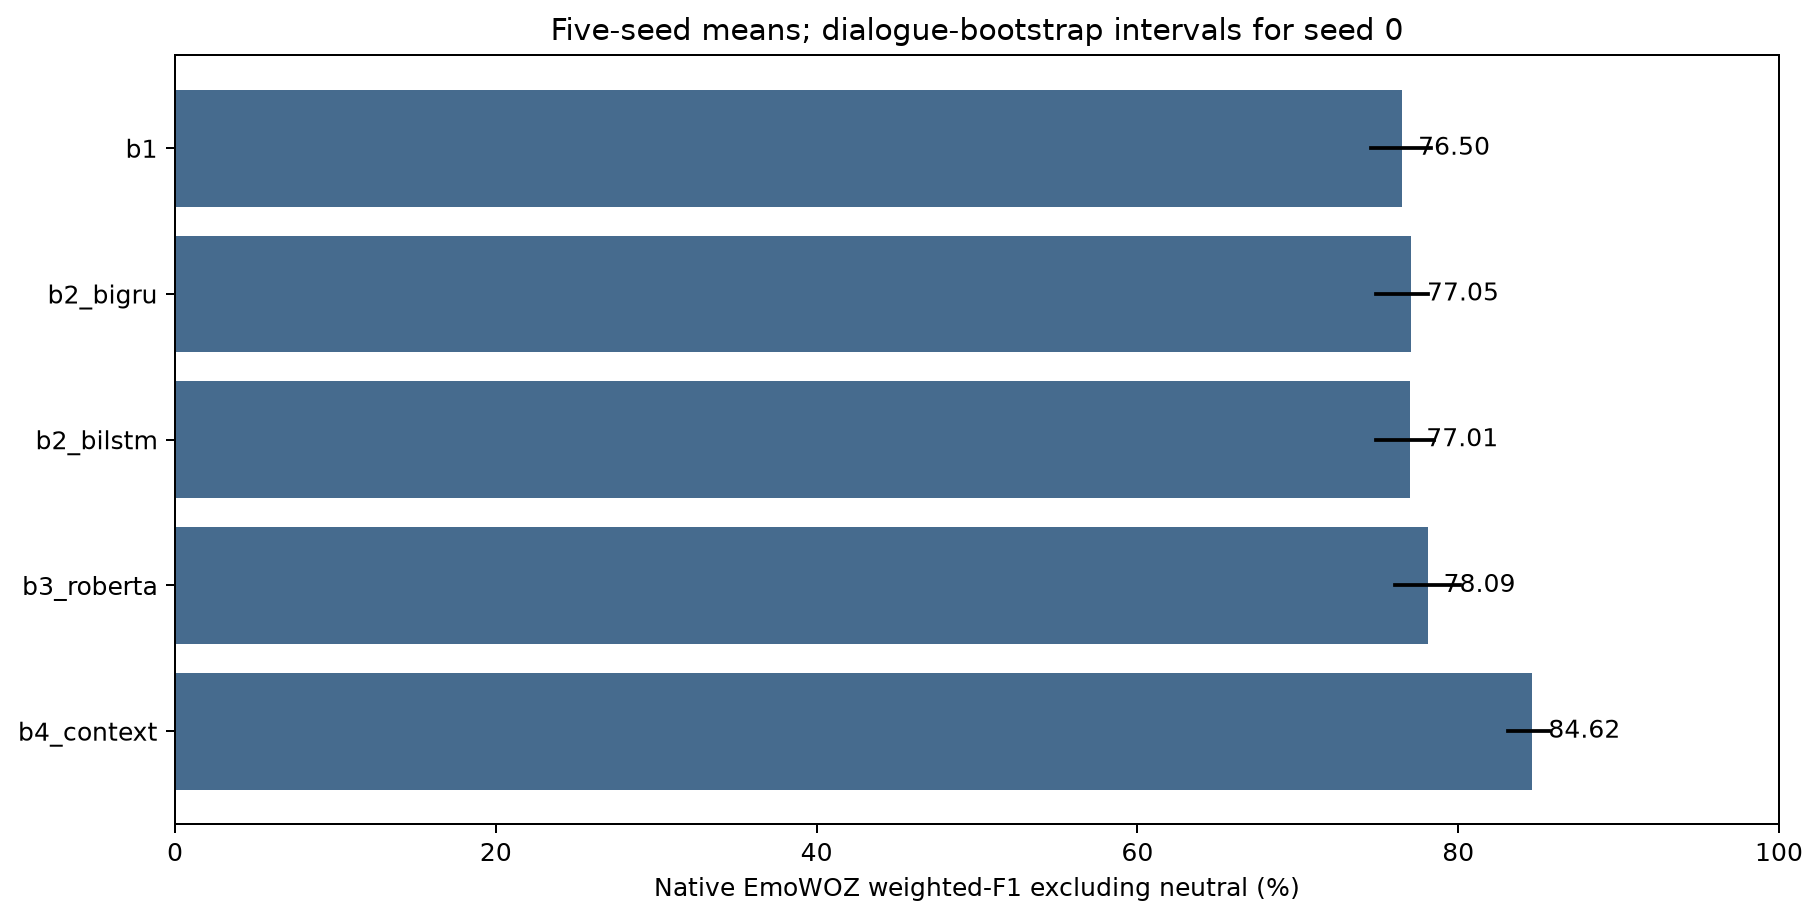

In [3]:
display(pd.read_csv("reports/b4/emowoz/comparison_b1_b2_b3_b4.csv"))
display(Image(filename="reports/b4/emowoz/figures/headline_comparison.png"))

## First / stable / shift
Gold strata are evaluation metadata, not inputs. Different class mixtures mean a higher shift-subset F1 does not establish dialogue understanding.

,model,group,weighted_f1_no_neutral
0,b1,stratum:first,0.489712
1,b1,stratum:stable,0.673813
2,b1,stratum:shift,0.819310
3,b2_bigru,stratum:first,0.448338
4,b2_bigru,stratum:stable,0.687220
5,b2_bigru,stratum:shift,0.828274
6,b2_bilstm,stratum:first,0.445490
7,b2_bilstm,stratum:stable,0.681308
8,b2_bilstm,stratum:shift,0.830054
9,b3_roberta,stratum:first,0.577534


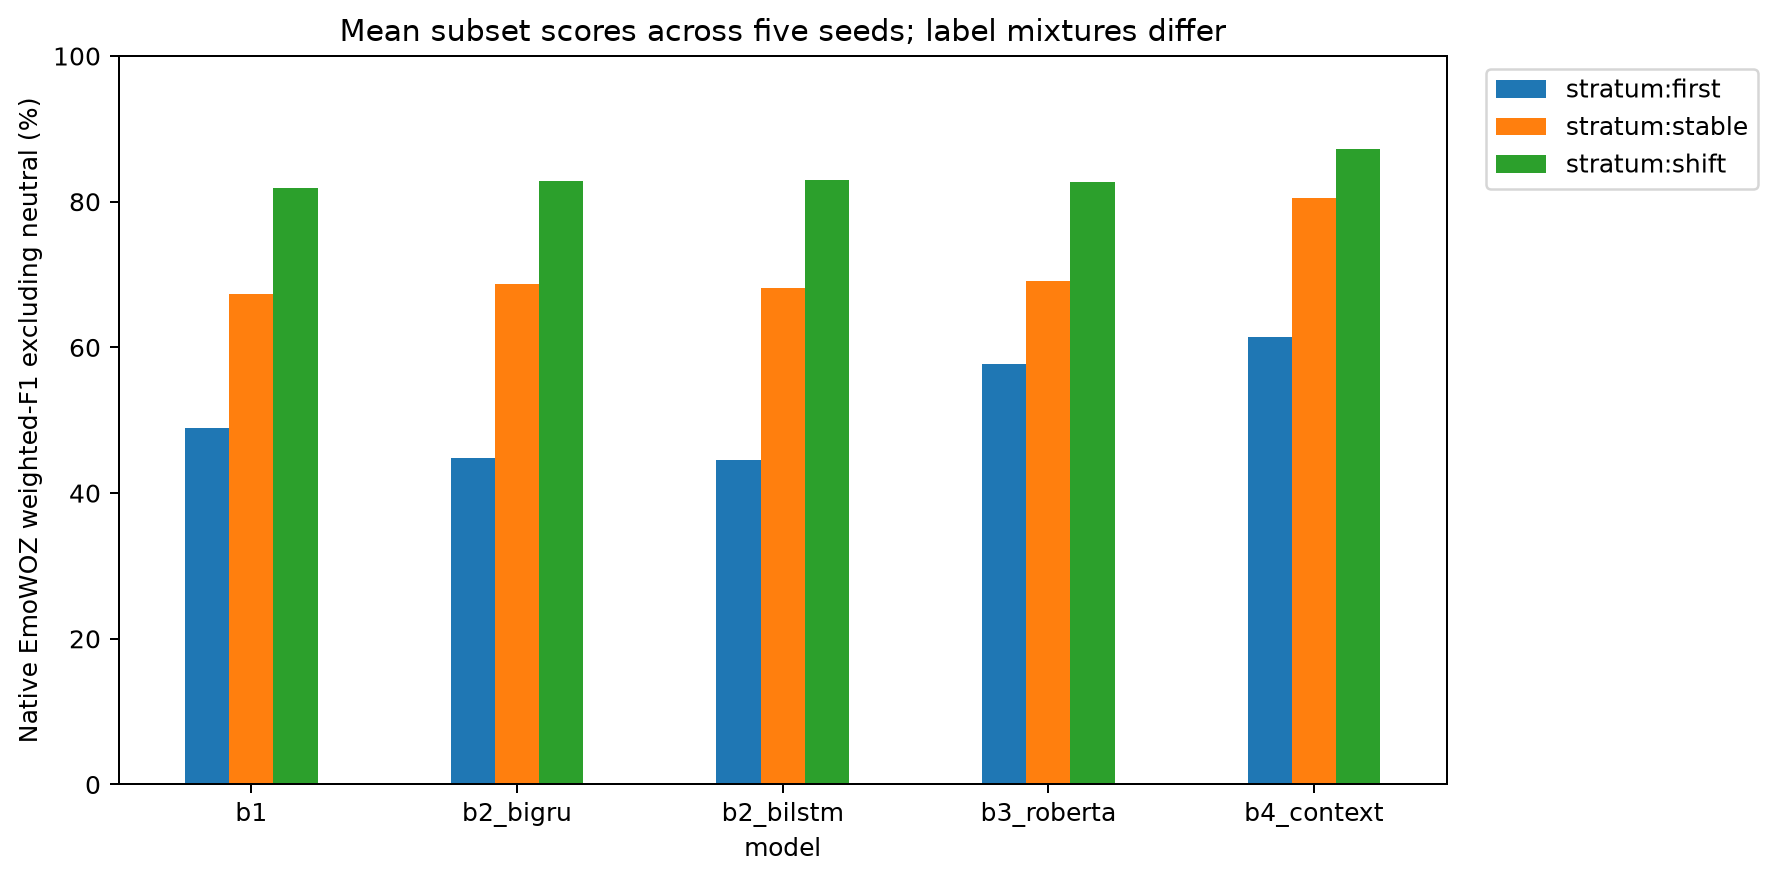

In [4]:
display(pd.read_csv("reports/b4/emowoz/figures/strata.csv"))
display(Image(filename="reports/b4/emowoz/figures/strata.png"))

## Paired context comparisons and E4 controls
Whole-dialogue intervals conditional on the five fixed seed pairs. Controls perturb inference inputs, without retraining.

In [5]:
display(pd.read_csv("reports/b4/emowoz/paired_comparisons.csv"))
display(pd.read_csv("reports/b4/emowoz/controls_summary.csv"))

,comparison,group,n,dialogues,metric,reference_mean,candidate_mean,mean_delta,ci95_low,ci95_high
0,b4_minus_b3,all,8634,1100,weighted_f1_no_neutral,0.780853,0.846203,0.065350,0.051738,0.081642
1,b4_minus_b3,first,1100,1100,weighted_f1_no_neutral,0.577534,0.614834,0.037299,-0.000938,0.079460
2,b4_minus_b3,stable,4884,1086,weighted_f1_no_neutral,0.691713,0.804997,0.113283,0.082895,0.145936
3,b4_minus_b3,shift,2650,1068,weighted_f1_no_neutral,0.827481,0.871876,0.044395,0.031735,0.056451
4,real_minus_none,all,8634,1100,weighted_f1_no_neutral,0.627989,0.846203,0.218214,0.188292,0.248395
5,real_minus_shuffled,all,8634,1100,weighted_f1_no_neutral,0.699006,0.846203,0.147198,0.117742,0.178716
6,real_minus_speakers,all,8634,1100,weighted_f1_no_neutral,0.846593,0.846203,-0.000389,-0.001230,0.000553


,mode,n,accuracy_mean,accuracy_std,weighted_f1_mean,weighted_f1_std,macro_f1_mean,macro_f1_std,micro_f1_no_neutral_mean,micro_f1_no_neutral_std,weighted_f1_no_neutral_mean,weighted_f1_no_neutral_std,macro_f1_no_neutral_mean,macro_f1_no_neutral_std
0,none,8634,0.857146,0.006745,0.824607,0.007412,0.482425,0.011026,0.695448,0.019308,0.627989,0.015534,0.411118,0.012503
1,shuffled,8634,0.881909,0.001139,0.855887,0.001979,0.529381,0.010492,0.770144,0.003198,0.699006,0.005273,0.463572,0.012225
2,speakers,8634,0.918555,0.003203,0.916928,0.002344,0.613260,0.005735,0.852191,0.003814,0.846593,0.002766,0.557542,0.006296


## Native-label demo
Large weights are shared separately. System turns are not neutral targets.

In [6]:
from emotionshift.models.roberta_context import RobertaContext

selection = json.loads(Path("reports/b4/emowoz/selection.json").read_text())
seed = selection["best_seed_on_dev"]
model = RobertaContext.load(f"models/b4_emowoz/seed{seed}", device="cpu")
print(model.labels)
print("Past window:", model.k)
speakers = ["user", "system", "user"]
texts = ["I need a hotel.", "I found a restaurant.", "That was not what I asked for."]
print(model.predict_dialogue(speakers, texts)[-1])

C:\Users\Lenovo\Documents\Codex\2026-10-30\referenced-chatgpt-conversation-this-is-an\work\emowoz-cuda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3406.79it/s]

['neutral', 'fearful', 'dissatisfied', 'apologetic', 'abusive', 'excited', 'satisfied']
Past window: all
dissatisfied


## Verification and interpretation
Report per-class metrics alongside weighted-F1; label imbalance can mask minority-class errors. These are in-domain experiments, with past-only context, without cross-dataset transfer.

In [7]:
display(json.loads(Path("reports/b4/emowoz/verification.json").read_text()))

{'prediction_csvs': 5,
 'targets_per_csv': 8634,
 'native_labels_verified': True,
 'dev_selection_verified': True,
 'metrics_recomputed': True,
 'checkpoint_round_trip_verified': True,
 'system_context_retained_user_targets_only': True,
 'e4_controls_verified': True,
 'paired_comparisons_verified': True,
 'prediction_sha256': {'predictions\\b4_emowoz_test_seed0.csv': 'd8efe513092d466c5e57888dc6fef65b90c89178298890a0f43259c6938aba69',
  'predictions\\b4_emowoz_test_seed1.csv': 'd227059dd1e7a5861d8aa83be5a7c061f0afdbd5ae6bb4e1ae656b39e952fba0',
  'predictions\\b4_emowoz_test_seed2.csv': 'a9c2ed9714a2384e4d558bd45f9351f71f0600802ca3c8d98c49932411578fd1',
  'predictions\\b4_emowoz_test_seed3.csv': 'c574782239f3442539ed99acaeab85bdf72137ff53884bf6cea03202f8031aab',
  'predictions\\b4_emowoz_test_seed4.csv': '22c39a437e9b9bb7d7fc4c050e37c3bbcc2c040ac51ac00ee1f3bba913724f2d'},
 'checkpoint_sha256': {'models\\b4_emowoz\\seed0\\model.safetensors': 'a4afa9ba90e6709cc7ad977d6670e95ccff4d163634c2d